# VibeMatch · 02 — Exploratory Data Analysis

In this notebook, we explore the Spotify data with visualizations: how songs are spread across decades, how the sound of music changed over time, which genres and artists stand out, and what limits our data has.

The goal is to understand which audio features really describe the "vibe" of a song, because these are the features VibeMatch will use to recommend similar tracks.

## Setup

In [1]:
# each notebook has its own memory, so we load everything again here
# this way the notebook works on its own, without running 01_data_loading first
import pandas as pd
import numpy as np

DATA_DIR = "../data/raw/Spotify/"

data = pd.read_csv(DATA_DIR + "data.csv")
genre_data = pd.read_csv(DATA_DIR + "data_by_genres.csv")
year_data = pd.read_csv(DATA_DIR + "data_by_year.csv")
artist_data = pd.read_csv(DATA_DIR + "data_by_artist.csv")

# we create the decade column again, the same way as in notebook 01 (1994 -> 199 -> 1990)
data["decade"] = data["year"].apply(lambda year: year // 10 * 10)

# quick check that everything loaded with the expected sizes
for name, df in [("data", data), ("genre_data", genre_data), ("year_data", year_data), ("artist_data", artist_data)]:
    print(f"{name}: {df.shape}")

data: (170653, 20)
genre_data: (2973, 14)
year_data: (100, 14)
artist_data: (28680, 15)


In [2]:
# plotly charts are interactive, but GitHub can't run the JavaScript needed to draw them,
# so they would show up as empty boxes there
# with this setting, each plotly chart is saved twice: the interactive version (for VS Code / Jupyter)
# and a PNG image made by kaleido (for GitHub)
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"

## 1. Distribution of tracks across decades

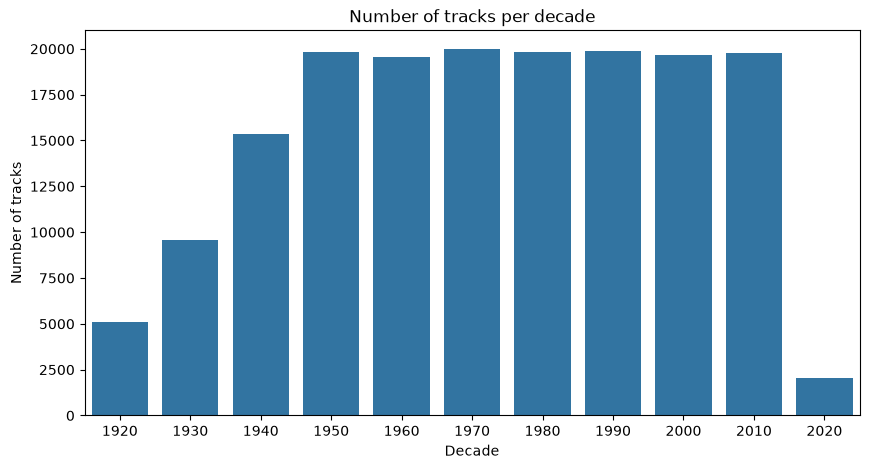

In [3]:
# seaborn is built on top of matplotlib and makes statistical charts with very little code
# matplotlib (plt) lets us add the title and adjust the figure size
import seaborn as sns
import matplotlib.pyplot as plt

# a count plot draws one bar per category with the number of rows in it, here the number of songs per decade
# we name the arguments: data= is the whole DataFrame and x= is the column to count
# (the shorter sns.countplot(data["decade"]) doesn't work anymore with recent seaborn versions:
# it treats each song as its own category and draws one bar per row instead of one bar per decade)
plt.figure(figsize=(10, 5))
sns.countplot(x="decade", data=data)
plt.title("Number of tracks per decade")
plt.xlabel("Decade")
plt.ylabel("Number of tracks")
plt.show()

**What we notice:** From the 1950s to the 2010s, every decade has close to 20,000 tracks (between 19,549 and 20,000), so the middle of the chart is almost flat. The 1920s (5,126), 1930s (9,549) and 1940s (15,378) have fewer songs, and the 2020s bar is tiny (2,030 tracks) because the data stops in 2020.

**Why it matters for VibeMatch:** The catalog has about the same number of songs for the 1950s as for the 2010s, which is not how people listen to music today. Older songs are over-represented and nothing after 2020 exists, so VibeMatch will naturally suggest more old tracks than a real streaming app would. A decade filter and a careful balance between eras will help.